In [6]:
import urllib.request

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

urllib.request.urlretrieve(url, "adult.data")

print("DONE")

DONE


In [13]:
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

names = [
    'age', 'workclass', 'fnlwgt', 'education', 'education-num',
    'marital-status', 'occupation', 'relationship', 'race', 'gender',
    'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income'
]

data = pd.read_csv(url, header=None, index_col=False, names=names)
data = data[['age', 'workclass', 'education', 'gender', 'hours-per-week', 'occupation', 'income']]

display(data.head())

,age,workclass,education,gender,hours-per-week,occupation,income
0,39,State-gov,Bachelors,Male,40,Adm-clerical,<=50K
1,50,Self-emp-not-inc,Bachelors,Male,13,Exec-managerial,<=50K
2,38,Private,HS-grad,Male,40,Handlers-cleaners,<=50K
3,53,Private,11th,Male,40,Handlers-cleaners,<=50K
4,28,Private,Bachelors,Female,40,Prof-specialty,<=50K


In [14]:
print(data.gender.value_counts())

gender
Male      21790
Female    10771
Name: count, dtype: int64


In [15]:
print("Original features:\n", list(data.columns))

data_dummies = pd.get_dummies(data)

print("Features after get_dummies:\n", list(data_dummies.columns))

Original features:
 ['age', 'workclass', 'education', 'gender', 'hours-per-week', 'occupation', 'income']
Features after get_dummies:
 ['age', 'hours-per-week', 'workclass_ ?', 'workclass_ Federal-gov', 'workclass_ Local-gov', 'workclass_ Never-worked', 'workclass_ Private', 'workclass_ Self-emp-inc', 'workclass_ Self-emp-not-inc', 'workclass_ State-gov', 'workclass_ Without-pay', 'education_ 10th', 'education_ 11th', 'education_ 12th', 'education_ 1st-4th', 'education_ 5th-6th', 'education_ 7th-8th', 'education_ 9th', 'education_ Assoc-acdm', 'education_ Assoc-voc', 'education_ Bachelors', 'education_ Doctorate', 'education_ HS-grad', 'education_ Masters', 'education_ Preschool', 'education_ Prof-school', 'education_ Some-college', 'gender_ Female', 'gender_ Male', 'occupation_ ?', 'occupation_ Adm-clerical', 'occupation_ Armed-Forces', 'occupation_ Craft-repair', 'occupation_ Exec-managerial', 'occupation_ Farming-fishing', 'occupation_ Handlers-cleaners', 'occupation_ Machine-op-ins

In [17]:
# Select features from 'age' through 'occupation_ Transport-moving'
features = data_dummies.loc[:, 'age':'occupation_ Transport-moving']

# Extract NumPy arrays
X = features.values
y = data_dummies['income_ >50K'].values

print("X.shape: {} y.shape: {}".format(X.shape, y.shape))

X.shape: (32561, 44) y.shape: (32561,)


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=0
)

# Scale the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create and train Logistic Regression
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train_scaled, y_train)

# Test accuracy
print("Test score: {:.2f}".format(
    logreg.score(X_test_scaled, y_test)
))

Test score: 0.81


In [20]:
# create a DataFrame with an integer feature and a categorical string feature
demo_df = pd.DataFrame({'Integer Feature': [0, 1, 2, 1],
'Categorical Feature': ['socks', 'fox', 'socks', 'box']})
display(demo_df)

,Integer Feature,Categorical Feature
0,0,socks
1,1,fox
2,2,socks
3,1,box


In [21]:
pd.get_dummies(demo_df)

,Integer Feature,Categorical Feature_box,Categorical Feature_fox,Categorical Feature_socks
0,0,False,False,True
1,1,False,True,False
2,2,False,False,True
3,1,True,False,False


In [22]:
demo_df['Integer Feature'] = demo_df['Integer Feature'].astype(str)
pd.get_dummies(demo_df, columns=['Integer Feature', 'Categorical Feature'])

,Integer Feature_0,Integer Feature_1,Integer Feature_2,Categorical Feature_box,Categorical Feature_fox,Categorical Feature_socks
0,True,False,False,False,False,True
1,False,True,False,False,True,False
2,False,False,True,False,False,True
3,False,True,False,True,False,False


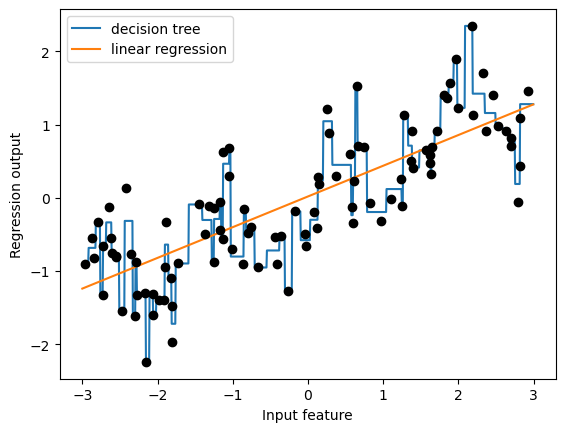

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import mglearn

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# Generate wave dataset
X, y = mglearn.datasets.make_wave(n_samples=100)

# Create points for prediction
line = np.linspace(-3, 3, 1000, endpoint=False).reshape(-1, 1)

# Decision Tree Regression
reg = DecisionTreeRegressor(min_samples_split=3).fit(X, y)
plt.plot(line, reg.predict(line), label="decision tree")

# Linear Regression
reg = LinearRegression().fit(X, y)
plt.plot(line, reg.predict(line), label="linear regression")

# Plot original data points
plt.plot(X[:, 0], y, 'o', c='k')

plt.ylabel("Regression output")
plt.xlabel("Input feature")
plt.legend(loc="best")
plt.show()

In [25]:
bins = np.linspace(-3, 3, 11)
print("bins: {}".format(bins))

bins: [-3.  -2.4 -1.8 -1.2 -0.6  0.   0.6  1.2  1.8  2.4  3. ]


In [26]:
which_bin = np.digitize(X, bins=bins)
print("\nData points:\n"
, X[:5])
print("\nBin membership for data points:\n"
, which_bin[:5])


Data points:
 [[-0.75275929]
 [ 2.70428584]
 [ 1.39196365]
 [ 0.59195091]
 [-2.06388816]]

Bin membership for data points:
 [[ 4]
 [10]
 [ 8]
 [ 6]
 [ 2]]


In [28]:
from sklearn.preprocessing import OneHotEncoder

# Create the OneHotEncoder
encoder = OneHotEncoder(sparse_output=False)

# Find the unique values in which_bin
encoder.fit(which_bin)

# Transform the data into one-hot encoding
X_binned = encoder.transform(which_bin)

# Display the first 5 rows
print(X_binned[:5])

[[0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [29]:
print("X_binned.shape: {}".format(X_binned.shape))

X_binned.shape: (100, 10)


Text(0.5, 0, 'Input feature')

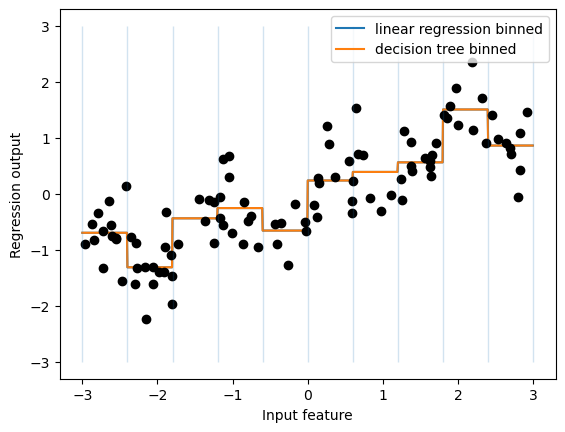

In [30]:
line_binned = encoder.transform(np.digitize(line, bins=bins))
reg = LinearRegression().fit(X_binned, y)
plt.plot(line, reg.predict(line_binned), label='linear regression binned')
reg = DecisionTreeRegressor(min_samples_split=3).fit(X_binned, y)
plt.plot(line, reg.predict(line_binned), label='decision tree binned')
plt.plot(X[:, 0], y, 'o', c='k')
plt.vlines(bins,
-3, 3, linewidth=1, alpha=.2)
plt.legend(loc="best")
plt.ylabel("Regression output")
plt.xlabel("Input feature")

In [31]:
X_combined = np.hstack([X, X_binned])
print(X_combined.shape)

(100, 11)


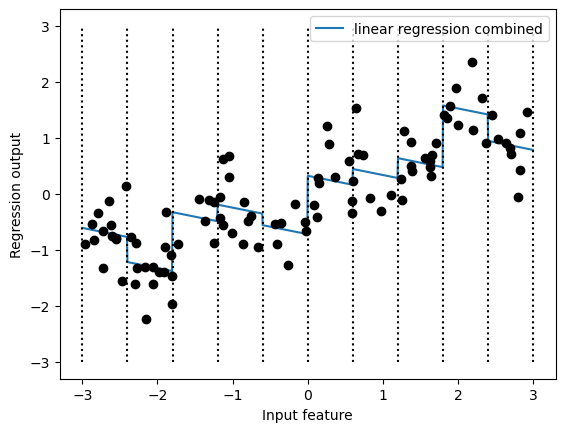

In [35]:
reg = LinearRegression().fit(X_combined, y)

line_combined = np.hstack([line, line_binned])

plt.plot(
    line,
    reg.predict(line_combined),
    label='linear regression combined'
)

for bin in bins:
    plt.plot([bin, bin], [-3, 3], ':', c='k')

plt.legend(loc="best")
plt.ylabel("Regression output")
plt.xlabel("Input feature")
plt.plot(X[:, 0], y, 'o', c='k')

plt.show()

In [36]:
X_product = np.hstack([X_binned, X * X_binned])
print(X_product.shape)

(100, 20)


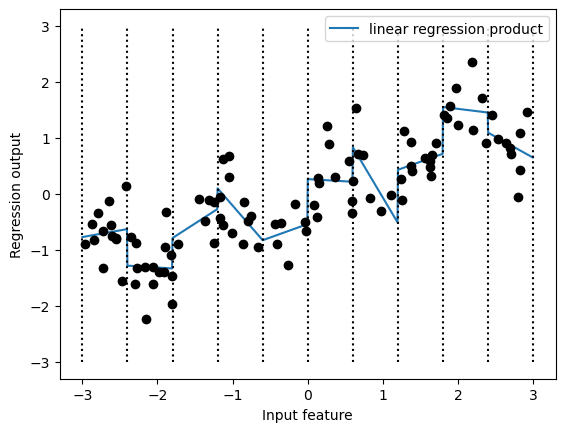

In [38]:
reg = LinearRegression().fit(X_product, y)

line_product = np.hstack([line_binned, line * line_binned])

plt.plot(
    line,
    reg.predict(line_product),
    label='linear regression product'
)

for bin in bins:
    plt.plot([bin, bin], [-3, 3], ':', c='k')

plt.plot(X[:, 0], y, 'o', c='k')

plt.ylabel("Regression output")
plt.xlabel("Input feature")
plt.legend(loc="best")

plt.show()

In [41]:
from sklearn.preprocessing import PolynomialFeatures

# Include polynomials up to x ** 10
# include_bias=False means we don't add a constant 1 feature
poly = PolynomialFeatures(degree=10, include_bias=False)

poly.fit(X)
X_poly = poly.transform(X)

print("X_poly.shape: {}".format(X_poly.shape))

X_poly.shape: (100, 10)


In [42]:
print("Entries of X:\n{}".format(X[:5]))
print("Entries of X_poly:\n{}".format(X_poly[:5]))

Entries of X:
[[-0.75275929]
 [ 2.70428584]
 [ 1.39196365]
 [ 0.59195091]
 [-2.06388816]]
Entries of X_poly:
[[-7.52759287e-01  5.66646544e-01 -4.26548448e-01  3.21088306e-01
  -2.41702204e-01  1.81943579e-01 -1.36959719e-01  1.03097700e-01
  -7.76077513e-02  5.84199555e-02]
 [ 2.70428584e+00  7.31316190e+00  1.97768801e+01  5.34823369e+01
   1.44631526e+02  3.91124988e+02  1.05771377e+03  2.86036036e+03
   7.73523202e+03  2.09182784e+04]
 [ 1.39196365e+00  1.93756281e+00  2.69701700e+00  3.75414962e+00
   5.22563982e+00  7.27390068e+00  1.01250053e+01  1.40936394e+01
   1.96178338e+01  2.73073115e+01]
 [ 5.91950905e-01  3.50405874e-01  2.07423074e-01  1.22784277e-01
   7.26822637e-02  4.30243318e-02  2.54682921e-02  1.50759786e-02
   8.92423917e-03  5.28271146e-03]
 [-2.06388816e+00  4.25963433e+00 -8.79140884e+00  1.81444846e+01
  -3.74481869e+01  7.72888694e+01 -1.59515582e+02  3.29222321e+02
  -6.79478050e+02  1.40236670e+03]]


In [44]:
print("Polynomial feature names:\n{}".format(
    poly.get_feature_names_out()
))

Polynomial feature names:
['x0' 'x0^2' 'x0^3' 'x0^4' 'x0^5' 'x0^6' 'x0^7' 'x0^8' 'x0^9' 'x0^10']


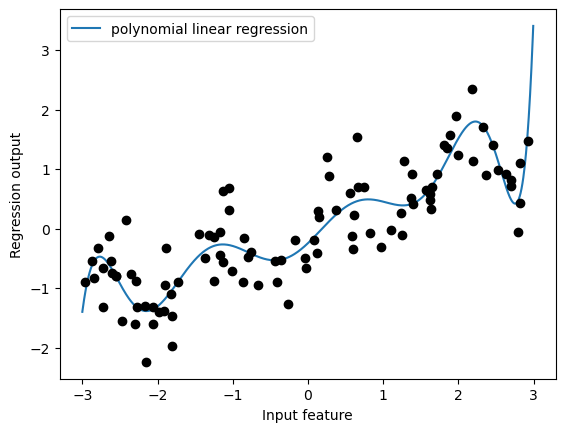

In [45]:
reg = LinearRegression().fit(X_poly, y)
line_poly = poly.transform(line)
plt.plot(line, reg.predict(line_poly), label='polynomial linear regression')
plt.plot(X[:, 0], y, 'o', c='k')
plt.ylabel("Regression output")
plt.xlabel("Input feature")
plt.legend(loc="best")

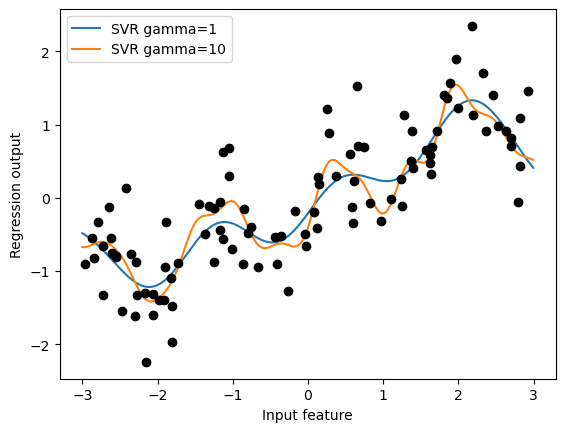

In [47]:
from sklearn.svm import SVR
import matplotlib.pyplot as plt

for gamma in [1, 10]:
    svr = SVR(gamma=gamma).fit(X, y)
    plt.plot(
        line,
        svr.predict(line),
        label='SVR gamma={}'.format(gamma)
    )

plt.plot(X[:, 0], y, 'o', c='k')
plt.ylabel("Regression output")
plt.xlabel("Input feature")
plt.legend(loc="best")
plt.show()

In [51]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures

# Load dataset
housing = fetch_california_housing()

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    housing.data,
    housing.target,
    random_state=0
)

# Rescale data
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create polynomial features
poly = PolynomialFeatures(degree=2, include_bias=False)
poly.fit(X_train_scaled)

X_train_poly = poly.transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

print("X_train.shape: {}".format(X_train.shape))
print("X_train_poly.shape: {}".format(X_train_poly.shape))

X_train.shape: (15480, 8)
X_train_poly.shape: (15480, 44)


In [53]:
print("Polynomial feature names:\n{}".format(
    poly.get_feature_names_out()
))

Polynomial feature names:
['x0' 'x1' 'x2' 'x3' 'x4' 'x5' 'x6' 'x7' 'x0^2' 'x0 x1' 'x0 x2' 'x0 x3'
 'x0 x4' 'x0 x5' 'x0 x6' 'x0 x7' 'x1^2' 'x1 x2' 'x1 x3' 'x1 x4' 'x1 x5'
 'x1 x6' 'x1 x7' 'x2^2' 'x2 x3' 'x2 x4' 'x2 x5' 'x2 x6' 'x2 x7' 'x3^2'
 'x3 x4' 'x3 x5' 'x3 x6' 'x3 x7' 'x4^2' 'x4 x5' 'x4 x6' 'x4 x7' 'x5^2'
 'x5 x6' 'x5 x7' 'x6^2' 'x6 x7' 'x7^2']


In [54]:
from sklearn.linear_model import Ridge
ridge = Ridge().fit(X_train_scaled, y_train)
print("Score without interactions: {:.3f}".format(
ridge.score(X_test_scaled, y_test)))
ridge = Ridge().fit(X_train_poly, y_train)
print("Score with interactions: {:.3f}".format(
ridge.score(X_test_poly, y_test)))

Score without interactions: 0.584
Score with interactions: 0.605


In [56]:
from sklearn.ensemble import RandomForestRegressor

# Random Forest without polynomial features
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=0
)
rf.fit(X_train_scaled, y_train)

print("Score without interactions: {:.3f}".format(
    rf.score(X_test_scaled, y_test)
))

# Random Forest with polynomial features
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=0
)
rf.fit(X_train_poly, y_train)

print("Score with interactions: {:.3f}".format(
    rf.score(X_test_poly, y_test)
))

Score without interactions: 0.794
Score with interactions: 0.807


In [57]:
rnd = np.random.RandomState(0)
X_org = rnd.normal(size=(1000, 3))
w = rnd.normal(size=3)
X = rnd.poisson(10 * np.exp(X_org))
y = np.dot(X_org, w)
print("Number of feature appearances:\n{}".format(np.bincount(X[:, 0])))

Number of feature appearances:
[28 38 68 48 61 59 45 56 37 40 35 34 36 26 23 26 27 21 23 23 18 21 10  9
 17  9  7 14 12  7  3  8  4  5  5  3  4  2  4  1  1  3  2  5  3  8  2  5
  2  1  2  3  3  2  2  3  3  0  1  2  1  0  0  3  1  0  0  0  1  3  0  1
  0  2  0  1  1  0  0  0  0  1  0  0  2  2  0  1  1  0  0  0  0  1  1  0
  0  0  0  0  0  0  1  0  0  0  0  0  1  1  0  0  1  0  0  0  0  0  0  0
  1  0  0  0  0  1  0  0  0  0  0  0  0  0  0  0  0  0  0  0  1]


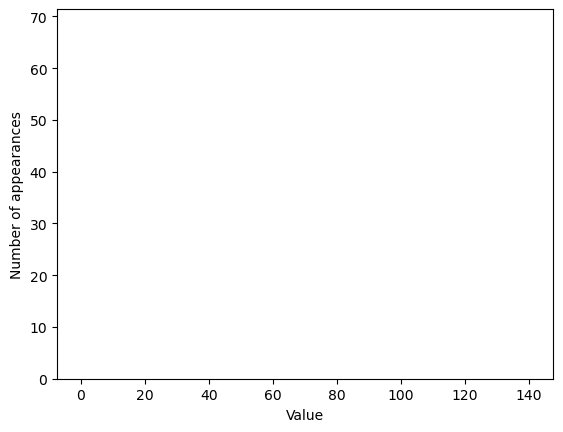

In [59]:
import numpy as np
import matplotlib.pyplot as plt

bins = np.bincount(X[:, 0].astype(int))

plt.bar(range(len(bins)), bins, color='w')
plt.ylabel("Number of appearances")
plt.xlabel("Value")
plt.show()

In [60]:
from sklearn.linear_model import Ridge
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
score = Ridge().fit(X_train, y_train).score(X_test, y_test)
print("Test score: {:.3f}".format(score))

Test score: 0.622


Text(0.5, 0, 'Value')

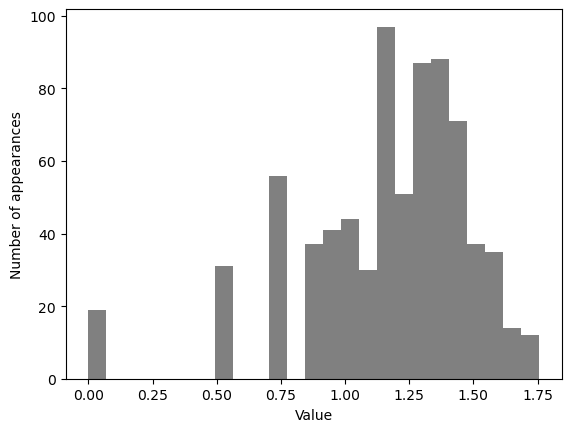

In [62]:
X_train_log = np.log(X_train + 1)
X_test_log = np.log(X_test + 1)
plt.hist(np.log(X_train_log[:, 0] + 1), bins=25, color='gray')
plt.ylabel("Number of appearances")
plt.xlabel("Value")

In [63]:
score = Ridge().fit(X_train_log, y_train).score(X_test_log, y_test)
print("Test score: {:.3f}".format(score))

Test score: 0.875


In [64]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SelectPercentile
from sklearn.model_selection import train_test_split
cancer = load_breast_cancer()
# get deterministic random numbers
rng = np.random.RandomState(42)
noise = rng.normal(size=(len(cancer.data), 50))
# add noise features to the data
# the first 30 features are from the dataset, the next 50 are noise
X_w_noise = np.hstack([cancer.data, noise])
X_train, X_test, y_train, y_test = train_test_split(
X_w_noise, cancer.target, random_state=0, test_size=.5)
# use f_classif (the default) and SelectPercentile to select 50% of features
select = SelectPercentile(percentile=50)
select.fit(X_train, y_train)
# transform training set
X_train_selected = select.transform(X_train)
print("X_train.shape: {}".format(X_train.shape))
print("X_train_selected.shape: {}".format(X_train_selected.shape))

X_train.shape: (284, 80)
X_train_selected.shape: (284, 40)


[ True  True  True  True  True  True  True  True  True False  True False
  True  True  True  True  True  True False False  True  True  True  True
  True  True  True  True  True  True False False False  True False  True
 False False  True False False False False  True False False  True False
 False  True False  True False False False False False False  True False
  True False False False False  True False  True False False False False
  True  True False  True False False False False]


Text(0.5, 0, 'Sample index')

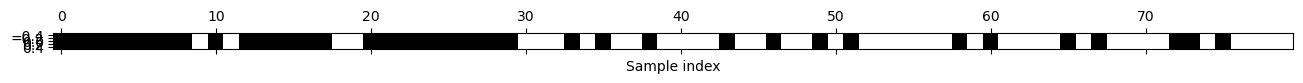

In [65]:
mask = select.get_support()
print(mask)
# visualize the mask -- black is True, white is False
plt.matshow(mask.reshape(1,
-1), cmap='gray_r')
plt.xlabel("Sample index")

In [68]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Scale all features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Scale selected features separately
X_train_selected_scaled = scaler.fit_transform(X_train_selected)
X_test_selected_scaled = scaler.transform(X_test_selected)

# Logistic Regression
lr = LogisticRegression(max_iter=2000)

# All features
lr.fit(X_train_scaled, y_train)

print("Score with all features: {:.3f}".format(
    lr.score(X_test_scaled, y_test)
))

# Selected features
lr.fit(X_train_selected_scaled, y_train)

print("Score with only selected features: {:.3f}".format(
    lr.score(X_test_selected_scaled, y_test)
))

Score with all features: 0.954
Score with only selected features: 0.965


In [70]:
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestClassifier
select = SelectFromModel(
RandomForestClassifier(n_estimators=100, random_state=42),
threshold="median")
select.fit(X_train, y_train)
X_train_l1 = select.transform(X_train)
print("X_train.shape: {}".format(X_train.shape))
print("X_train_l1.shape: {}".format(X_train_l1.shape))

X_train.shape: (284, 80)
X_train_l1.shape: (284, 40)


Text(0.5, 0, 'Sample index')

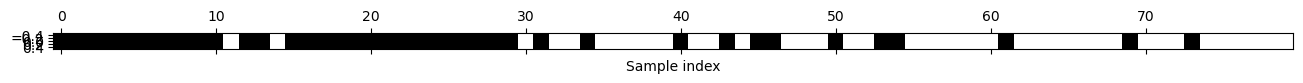

In [71]:
mask = select.get_support()
# visualize the mask -- black is True, white is False
plt.matshow(mask.reshape(1,
-1), cmap='gray_r')
plt.xlabel("Sample index")

In [73]:
from sklearn.linear_model import LogisticRegression

# Transform test data using the same selector
X_test_l1 = select.transform(X_test)

# Train Logistic Regression using selected features
score = LogisticRegression(max_iter=5000).fit(
    X_train_l1, y_train
).score(
    X_test_l1, y_test
)

print("Test score: {:.3f}".format(score))

Test score: 0.947


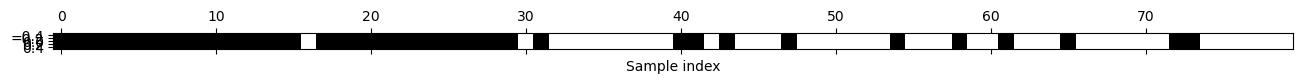

In [75]:
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

select = RFE(
    RandomForestClassifier(n_estimators=100, random_state=42),
    n_features_to_select=40
)

# Fit RFE
select.fit(X_train, y_train)

# Visualize the selected features
mask = select.get_support()

plt.matshow(mask.reshape(1, -1), cmap='gray_r')
plt.xlabel("Sample index")
plt.show()

In [77]:
from sklearn.linear_model import LogisticRegression

# Transform the training and test data using RFE
X_train_rfe = select.transform(X_train)
X_test_rfe = select.transform(X_test)

# Train Logistic Regression
lr = LogisticRegression(max_iter=5000)
lr.fit(X_train_rfe, y_train)

# Calculate test score
score = lr.score(X_test_rfe, y_test)

print("Test score: {:.3f}".format(score))

Test score: 0.951


In [78]:
print("Test score: {:.3f}".format(select.score(X_test, y_test)))

Test score: 0.947


In [80]:
citibike = mglearn.datasets.load_citibike()
print("Citi Bike data:\n{}".format(citibike.head()))

Citi Bike data:
starttime
2015-08-01 00:00:00     3
2015-08-01 03:00:00     0
2015-08-01 06:00:00     9
2015-08-01 09:00:00    41
2015-08-01 12:00:00    39
Freq: 3h, Name: one, dtype: int64


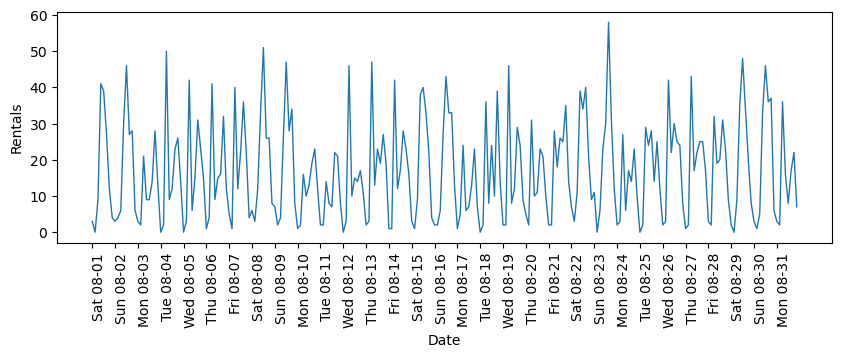

In [81]:
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 3))

xticks = pd.date_range(
    start=citibike.index.min(),
    end=citibike.index.max(),
    freq='D'
)

plt.xticks(
    xticks,
    xticks.strftime("%a %m-%d"),
    rotation=90,
    ha="left"
)

plt.plot(citibike, linewidth=1)

plt.xlabel("Date")
plt.ylabel("Rentals")

plt.show()

Test-set R^2: -0.04


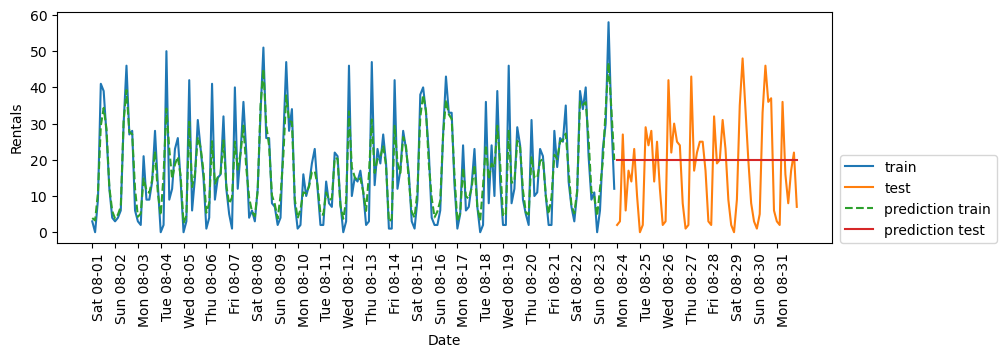

In [87]:
# Extract the target values (number of rentals)
y = citibike.values

# Convert the time to POSIX/Unix timestamp
X = citibike.index.astype("int64").values.reshape(-1, 1)

# Use the first 184 data points for training
n_train = 184


# Function to evaluate and plot a regressor
def eval_on_features(features, target, regressor):

    # Split features into training and test sets
    X_train, X_test = features[:n_train], features[n_train:]

    # Split target into training and test sets
    y_train, y_test = target[:n_train], target[n_train:]

    # Train the model
    regressor.fit(X_train, y_train)

    # Test-set R² score
    print("Test-set R^2: {:.2f}".format(
        regressor.score(X_test, y_test)
    ))

    # Predictions
    y_pred = regressor.predict(X_test)
    y_pred_train = regressor.predict(X_train)

    # Plot
    plt.figure(figsize=(10, 3))

    plt.xticks(
        range(0, len(X), 8),
        xticks.strftime("%a %m-%d"),
        rotation=90,
        ha="left"
    )

    plt.plot(
        range(n_train),
        y_train,
        label="train"
    )

    plt.plot(
        range(n_train, n_train + len(y_test)),
        y_test,
        '-',
        label="test"
    )

    plt.plot(
        range(n_train),
        y_pred_train,
        '--',
        label="prediction train"
    )

    plt.plot(
        range(n_train, n_train + len(y_test)),
        y_pred,
        label="prediction test"
    )

    plt.legend(loc=(1.01, 0))
    plt.xlabel("Date")
    plt.ylabel("Rentals")
    plt.show()


# Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

regressor = RandomForestRegressor(
    n_estimators=100,
    random_state=0
)

# Evaluate the model
eval_on_features(X, y, regressor)

Test-set R^2: 0.60


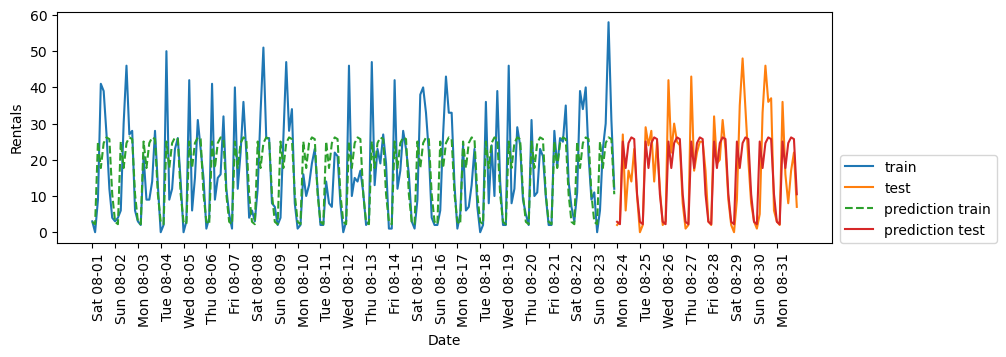

In [89]:
X_hour = citibike.index.hour.values.reshape(-1, 1)

eval_on_features(X_hour, y, regressor)

Test-set R^2: 0.84


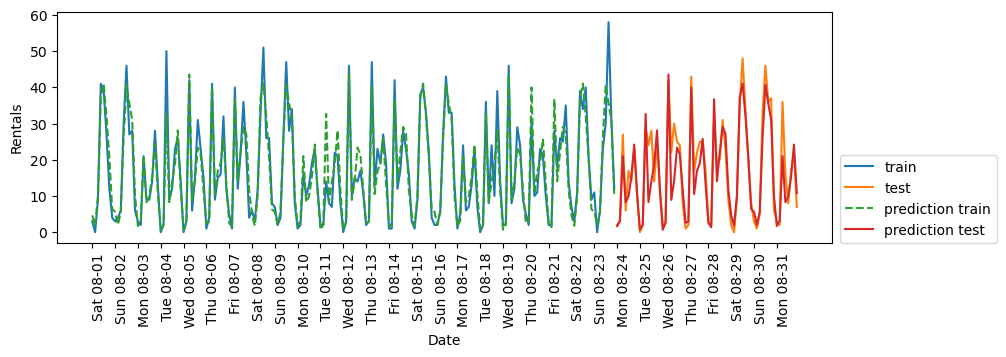

In [91]:
import numpy as np

X_hour_week = np.hstack([
    citibike.index.dayofweek.values.reshape(-1, 1),
    citibike.index.hour.values.reshape(-1, 1)
])

eval_on_features(X_hour_week, y, regressor)

Test-set R^2: 0.13


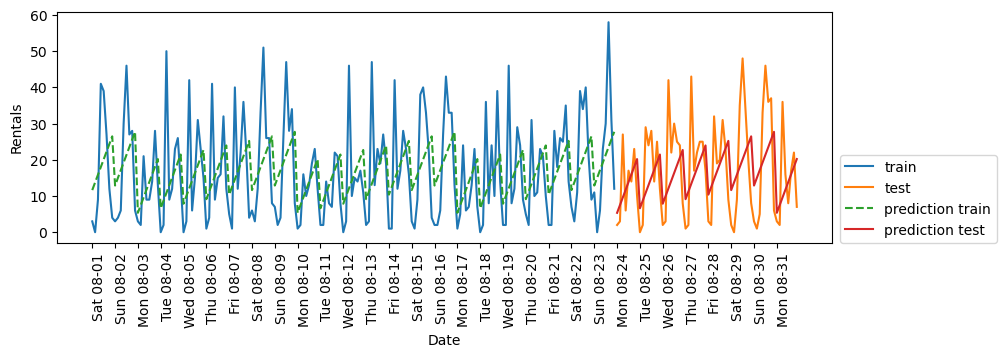

In [92]:
from sklearn.linear_model import LinearRegression
eval_on_features(X_hour_week, y, LinearRegression())

Test-set R^2: 0.62


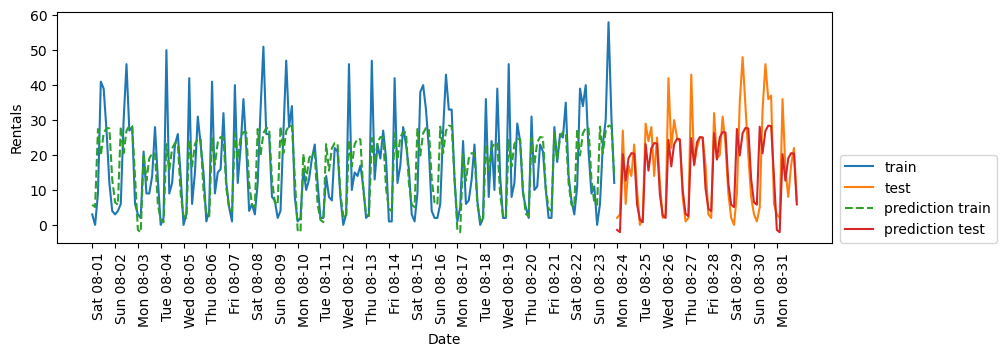

In [94]:
enc = OneHotEncoder()
X_hour_week_onehot = enc.fit_transform(X_hour_week).toarray()
eval_on_features(X_hour_week_onehot, y, Ridge())

Test-set R^2: 0.85


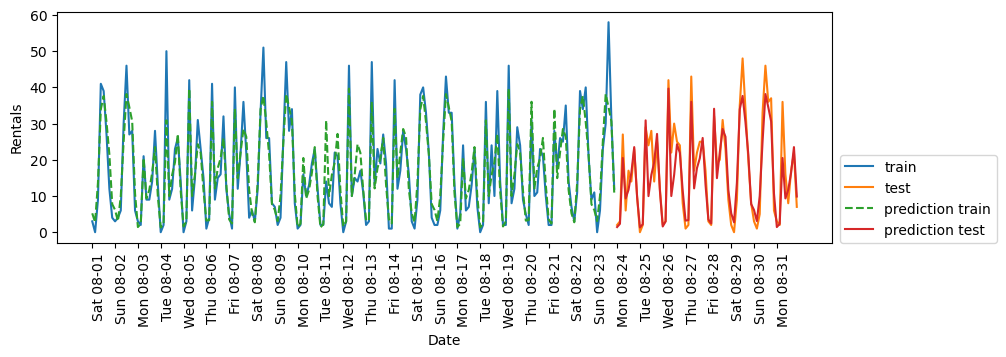

In [95]:
poly_transformer = PolynomialFeatures(degree=2, interaction_only=True,
include_bias=False)
X_hour_week_onehot_poly = poly_transformer.fit_transform(X_hour_week_onehot)
lr = Ridge()
eval_on_features(X_hour_week_onehot_poly, y, lr)

In [98]:
hour = ["%02d:00" % i for i in range(0, 24, 3)]
day = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
features = day + hour
features_poly = poly_transformer.get_feature_names(features)
features_nonzero = np.array(features_poly)[lr.coef_ != 0]
coef_nonzero = lr.coef_[lr.coef_ != 0]
plt.figure(figsize=(15, 2))
plt.plot(coef_nonzero, 'o')
plt.xticks(np.arange(len(coef_nonzero)), features_nonzero, rotation=90)
plt.xlabel("Feature magnitude")
plt.ylabel("Feature")

AttributeError: 'PolynomialFeatures' object has no attribute 'get_feature_names'